# Online Food Delivery Analysis — Raw Dataset Audit

1. Load the raw file and inspect its structure.
2. Check duplicates, identifiers, missingness, data types, and category values.
3. Profile numerical distributions and potential outliers.
4. Check business-rule consistency between order status, delivery time, ratings, and financial fields.
5. Examine the distance–delivery-time relationship.
6. Export audit tables and a concise text summary to `reports/`.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme()

print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python executable: d:\online food delivery analysis final\.venv\Scripts\python.exe
Pandas version: 3.0.6
NumPy version: 2.4.6


## 1. Configure project paths


In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "data" / "raw").is_dir():
            return candidate
    # Common case: notebook is run from the notebooks folder before data is populated.
    if start.name.lower() == "notebooks":
        return start.parent
    return start

PROJECT_ROOT = find_project_root(Path.cwd())
RAW_FILE = PROJECT_ROOT / "data" / "raw" / "online_food_delivery_analysis_dataset.csv"
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Current working directory:", Path.cwd())
print("Project root:", PROJECT_ROOT)
print("Raw dataset path:", RAW_FILE)
print("Dataset exists:", RAW_FILE.exists())

if not RAW_FILE.exists():
    raise FileNotFoundError(
        "Raw dataset not found. Save the downloaded CSV to: "
        f"{RAW_FILE}\nIf your filename differs, update RAW_FILE in this cell."
    )

Current working directory: d:\online food delivery analysis final\notebooks
Project root: D:\online food delivery analysis final
Raw dataset path: D:\online food delivery analysis final\data\raw\online_food_delivery_analysis_dataset.csv
Dataset exists: True


## 2. Load the raw dataset


In [3]:
df_raw = pd.read_csv(RAW_FILE, low_memory=False)

print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]:,}")
display(df_raw.head(10))

Rows: 100,000
Columns: 25


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,Order_Time,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST03987,24.000,Male,Chennai,OMR,RES1298,Restaurant_1298,Fast Food,06/05/2024,14:11,109.000,19.070,"1,901.200",100.000,"1,801.200",COD,Delivered,Not Applicable,DP00866,4.400,3.200,Weekday,False,0.029
1,ORD000002,CUST01917,45.000,Female,Hyderabad,NaN,RES1191,Restaurant_1191,Chinese,05/11/2024,04:09,53.000,2.640,489.780,20.000,469.780,Credit Card,Delivered,Not Applicable,DP04095,4.600,4.300,Weekend,False,0.214
2,ORD000003,CUST13338,57.000,Male,Bengaluru,Indiranagar,RES0681,Restaurant_0681,Indian,02/02/2024,01:23,100.000,16.300,468.450,0.000,468.450,UPI,Delivered,Not Applicable,DP01853,4.600,3.500,Weekday,False,0.204
3,ORD000004,CUST09787,66.000,Female,Chennai,Velachery,RES0453,Restaurant_0453,Indian,03/27/2024,19:06,47.000,0.800,731.180,50.000,681.180,UPI,Delivered,Not Applicable,DP04885,5.000,4.300,Weekday,True,0.293
4,ORD000005,CUST15793,43.000,Female,Chennai,Anna Nagar,RES0268,Restaurant_0268,Indian,07/11/2024,07:47,NaN,18.930,571.870,100.000,471.870,UPI,Preparing,Not Applicable,DP04754,NaN,4.700,Weekday,True,NaN
5,ORD000006,CUST17025,24.000,Male,Delhi,Rohini,RES0162,Restaurant_0162,Indian,09/06/2024,02:49,35.000,6.000,603.680,50.000,553.680,UPI,Delivered,Not Applicable,DP02931,4.100,3.400,Weekday,False,0.213
6,ORD000007,CUST06898,51.000,Male,Chennai,T. Nagar,RES0119,Restaurant_0119,Chinese,11/19/2024,06:00,58.000,5.350,791.420,50.000,741.420,Wallet,Delivered,Not Applicable,DP00376,4.900,NaN,Weekday,False,0.260
7,ORD000008,CUST07673,67.000,Female,Bengaluru,Koramangala,RES1106,Restaurant_1106,Indian,02/10/2024,17:06,42.000,1.270,"1,218.400",50.000,"1,168.400",UPI,Delivered,Not Applicable,DP03071,4.000,3.700,Weekend,False,0.224
8,ORD000009,CUST04893,47.000,Female,Bengaluru,Jayanagar,RES1191,Restaurant_1191,Indian,10/20/2024,00:08,83.000,12.100,"1,876.130",20.000,"1,856.130",UPI,Delivered,Not Applicable,DP03294,3.500,4.000,Weekend,False,0.171
9,ORD000010,CUST16068,55.000,Female,Delhi,Pitampura,RES0632,Restaurant_0632,South Indian,10/09/2024,00:20,NaN,4.360,"1,711.470",200.000,"1,511.470",Wallet,Preparing,Not Applicable,DP01673,NaN,4.600,Weekday,False,NaN


In [4]:
print("Column names:")
for index, column in enumerate(df_raw.columns, start=1):
    print(f"{index:02d}. {column}")

print("\nDataFrame info:")
df_raw.info()

Column names:
01. Order_ID
02. Customer_ID
03. Customer_Age
04. Customer_Gender
05. City
06. Area
07. Restaurant_ID
08. Restaurant_Name
09. Cuisine_Type
10. Order_Date
11. Order_Time
12. Delivery_Time_Min
13. Distance_km
14. Order_Value
15. Discount_Applied
16. Final_Amount
17. Payment_Mode
18. Order_Status
19. Cancellation_Reason
20. Delivery_Partner_ID
21. Delivery_Rating
22. Restaurant_Rating
23. Order_Day
24. Peak_Hour
25. Profit_Margin

DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Order_ID             100000 non-null  str    
 1   Customer_ID          100000 non-null  str    
 2   Customer_Age         98524 non-null   float64
 3   Customer_Gender      99010 non-null   str    
 4   City                 99452 non-null   str    
 5   Area                 99500 non-null   str    
 6   Restaurant_ID        10000

## 3. Duplicate and identifier checks

In [5]:
duplicate_rows = int(df_raw.duplicated().sum())
print("Exact duplicate rows:", duplicate_rows)

id_column = "Order_ID"
if id_column in df_raw.columns:
    print("Missing Order_ID:", int(df_raw[id_column].isna().sum()))
    print("Unique Order_ID:", int(df_raw[id_column].nunique(dropna=True)))
    print("Duplicate non-null Order_ID values:",
          int(df_raw.loc[df_raw[id_column].notna(), id_column].duplicated().sum()))
else:
    print(f"Identifier check skipped: '{id_column}' column not found.")

Exact duplicate rows: 0
Missing Order_ID: 0
Unique Order_ID: 100000
Duplicate non-null Order_ID values: 0


## 4. Missing-value audit

,Missing_Count,Missing_Percentage,Data_Type,Distinct_Non_Null
Delivery_Rating,14379,14.380,float64,32
Delivery_Time_Min,10712,10.710,float64,139
Profit_Margin,10712,10.710,float64,431
Restaurant_Rating,2586,2.590,float64,32
Customer_Age,1476,1.480,float64,53
Distance_km,1334,1.330,float64,3162
Final_Amount,997,1.000,float64,76514
Customer_Gender,990,0.990,str,4
City,548,0.550,str,7
Discount_Applied,500,0.500,float64,5466


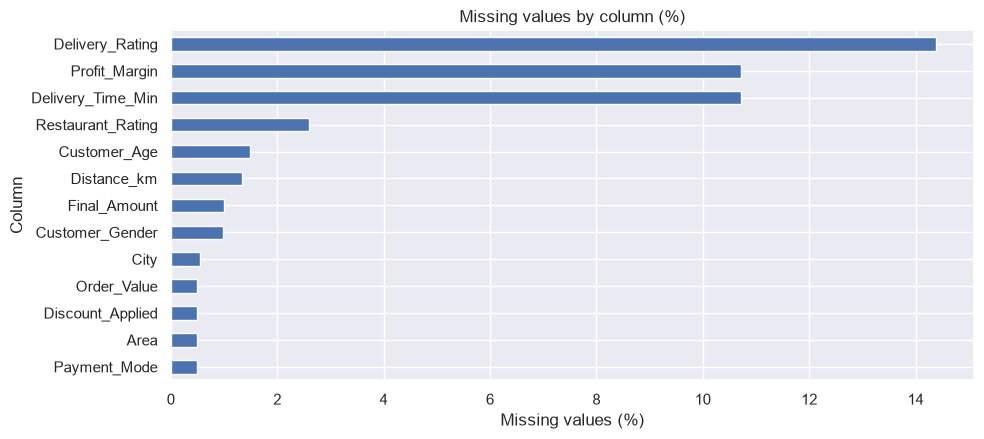

In [6]:
missing_audit = pd.DataFrame({
    "Missing_Count": df_raw.isna().sum(),
    "Missing_Percentage": (df_raw.isna().mean() * 100).round(2),
    "Data_Type": df_raw.dtypes.astype(str),
    "Distinct_Non_Null": df_raw.nunique(dropna=True)
}).sort_values("Missing_Percentage", ascending=False)

display(missing_audit)

missing_plot = missing_audit[missing_audit["Missing_Count"] > 0]
if not missing_plot.empty:
    ax = missing_plot["Missing_Percentage"].sort_values().plot(
        kind="barh", figsize=(10, max(4, 0.35 * len(missing_plot))),
        title="Missing values by column (%)"
    )
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

## 5. Numerical profiling and potential outliers


In [7]:
numeric_columns = df_raw.select_dtypes(include="number").columns.tolist()

if numeric_columns:
    numeric_summary = df_raw[numeric_columns].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).T
    numeric_summary["Missing_Count"] = df_raw[numeric_columns].isna().sum()
    display(numeric_summary)
else:
    numeric_summary = pd.DataFrame()
    print("No numeric columns detected.")

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,Missing_Count
Customer_Age,"98,524.000",43.950,15.304,18.000,18.000,20.000,31.000,44.000,57.000,68.000,70.000,70.000,1476
Delivery_Time_Min,"89,288.000",61.496,19.672,12.000,27.000,35.000,48.000,59.000,72.000,98.000,123.000,150.000,10712
Distance_km,"98,666.000",8.892,5.878,0.800,1.120,1.990,4.530,7.550,11.820,20.457,28.280,35.000,1334
Order_Value,"99,501.000","1,085.017",626.832,183.310,255.680,351.060,623.130,945.040,"1,393.400","2,302.900","3,146.120","5,000.000",499
Discount_Applied,"99,500.000",76.088,83.284,0.000,0.000,0.000,0.000,50.000,115.180,271.272,300.000,300.000,500
Final_Amount,"99,003.000","1,008.933",627.608,120.840,189.141,278.023,543.745,867.020,"1,319.105","2,225.874","3,073.720","5,000.000",997
Delivery_Rating,"85,621.000",4.177,0.472,1.400,3.000,3.400,3.900,4.200,4.500,5.000,5.000,5.000,14379
Restaurant_Rating,"97,414.000",4.087,0.527,1.700,2.800,3.200,3.700,4.100,4.500,5.000,5.000,5.000,2586
Profit_Margin,"89,288.000",0.176,0.072,-0.050,0.007,0.057,0.128,0.177,0.225,0.295,0.343,0.380,10712


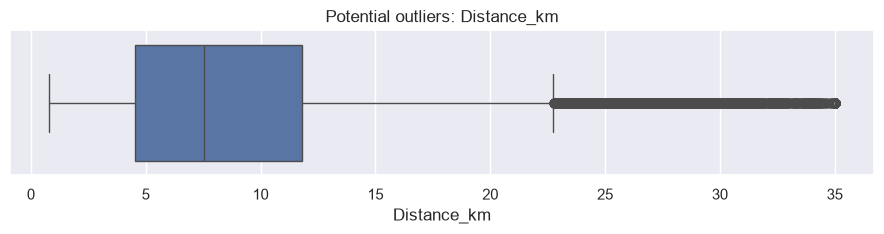

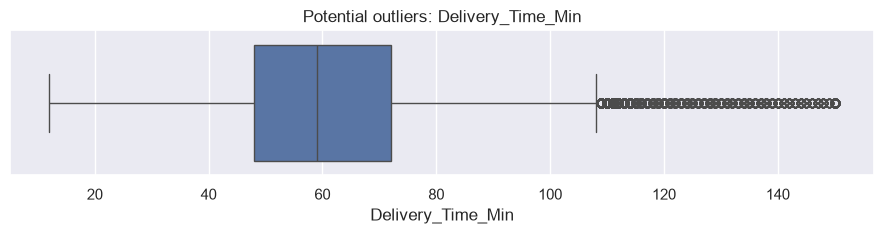

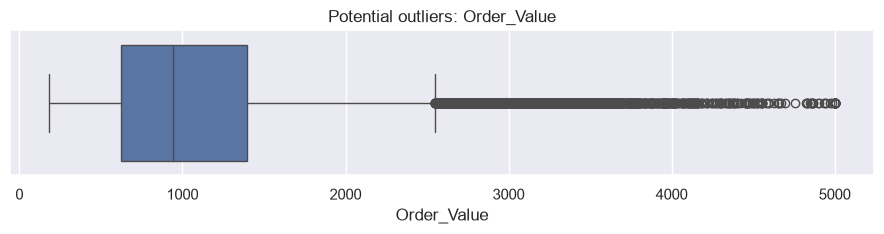

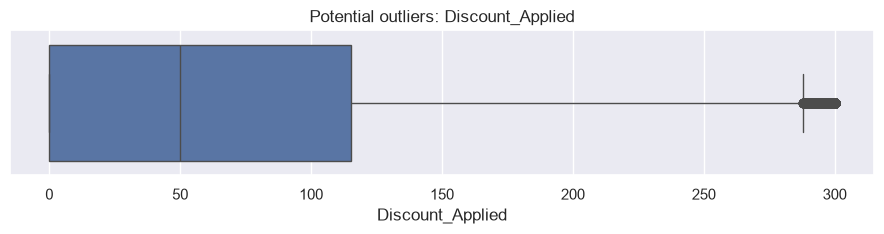

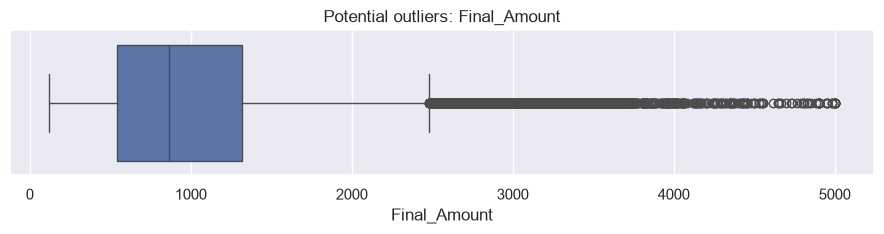

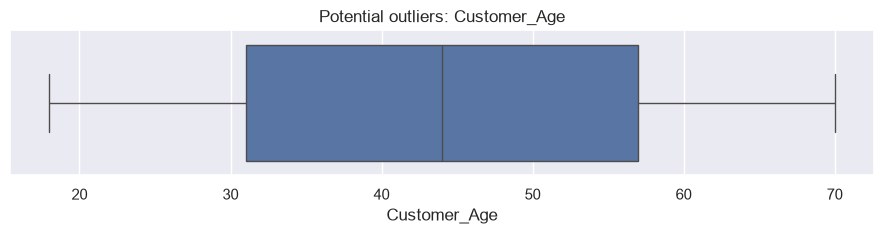

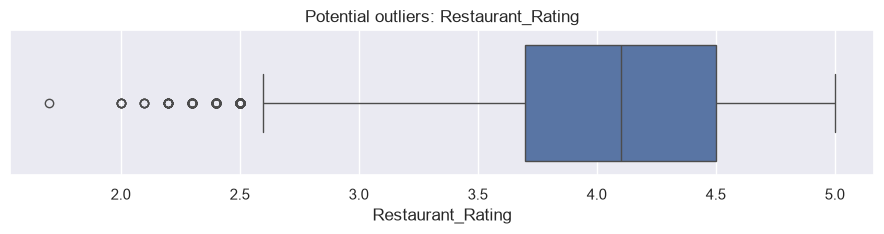

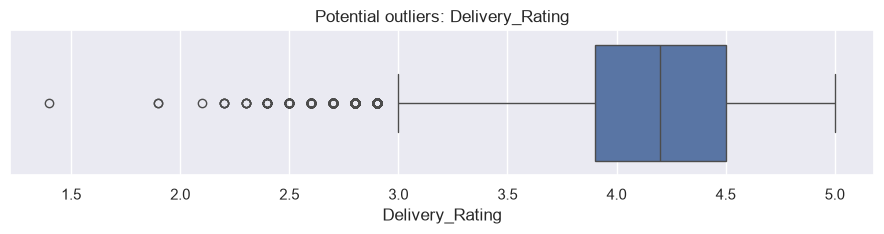

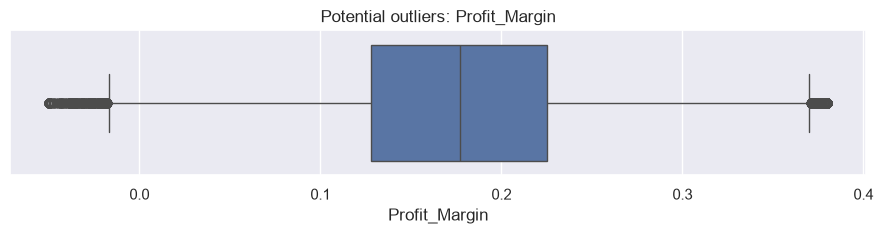

In [8]:
# Boxplots for selected numeric fields, when present.
candidate_numeric = [
    "Distance_km", "Delivery_Time_Min", "Preparation_Time_Min",
    "Order_Value", "Discount_Applied", "Delivery_Fee", "Tax",
    "Final_Amount", "Customer_Age", "Restaurant_Rating",
    "Delivery_Rating", "Profit_Margin"
]
plot_columns = [column for column in candidate_numeric if column in df_raw.columns]

for column in plot_columns:
    series = pd.to_numeric(df_raw[column], errors="coerce").dropna()
    if series.empty:
        continue
    plt.figure(figsize=(9, 2.5))
    sns.boxplot(x=series)
    plt.title(f"Potential outliers: {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

## 6. Categorical value audit

In [9]:
candidate_categories = [
    "Customer_Gender", "City", "Area", "Cuisine_Type", "Payment_Mode",
    "Order_Status", "Cancellation_Reason", "Order_Day", "Peak_Hour",
    "Traffic_Level", "Weather"
]

category_tables = {}
for column in candidate_categories:
    if column in df_raw.columns:
        counts = df_raw[column].value_counts(dropna=False).rename_axis(column).reset_index(name="Count")
        category_tables[column] = counts
        print(f"\n--- {column} ---")
        display(counts.head(50))


--- Customer_Gender ---


,Customer_Gender,Count
0,Female,46685
1,Male,46420
2,Prefer not to say,3940
3,Non-binary,1965
4,NaN,990



--- City ---


,City,Count
0,Chennai,21880
1,Bengaluru,17906
2,Mumbai,16889
3,Hyderabad,12777
4,Delhi,12150
5,Pune,9909
6,Kolkata,7941
7,NaN,548



--- Area ---


...

,Cancellation_Reason,Count
0,Not Applicable,93857
1,Restaurant Issue,1710
2,Customer Cancelled,1634
3,Rider Unavailable,1212
4,Incorrect Address,849
5,Payment Issue,738



--- Order_Day ---


,Order_Day,Count
0,Weekday,71595
1,Weekend,28405



--- Peak_Hour ---


,Peak_Hour,Count
0,False,62872
1,True,37128


## 7. Business-rule and logical consistency checks


In [10]:
def count_condition(mask: pd.Series) -> int:
    # Count True values only; missing values in a condition are treated as False.
    return int(mask.fillna(False).sum())

checks = {}

def add_check(name, condition):
    checks[name] = count_condition(condition)

if "Order_ID" in df_raw:
    add_check("Missing Order_ID", df_raw["Order_ID"].isna())

for column, label in [
    ("Order_Value", "Negative Order_Value"),
    ("Discount_Applied", "Negative Discount_Applied"),
    ("Delivery_Fee", "Negative Delivery_Fee"),
    ("Tax", "Negative Tax"),
    ("Final_Amount", "Negative Final_Amount"),
    ("Distance_km", "Non-positive Distance_km"),
    ("Delivery_Time_Min", "Non-positive Delivery_Time_Min"),
    ("Preparation_Time_Min", "Non-positive Preparation_Time_Min"),
]:
    if column in df_raw:
        values = pd.to_numeric(df_raw[column], errors="coerce")
        add_check(label, values < 0 if "Negative" in label else values <= 0)

for column, label in [
    ("Customer_Age", "Customer_Age outside 18–100"),
    ("Restaurant_Rating", "Restaurant_Rating outside 1–5"),
    ("Delivery_Rating", "Delivery_Rating outside 1–5"),
]:
    if column in df_raw:
        values = pd.to_numeric(df_raw[column], errors="coerce")
        low, high = (18, 100) if column == "Customer_Age" else (1, 5)
        add_check(label, (values < low) | (values > high))

if "Profit_Margin" in df_raw:
    margin = pd.to_numeric(df_raw["Profit_Margin"], errors="coerce")
    add_check("Profit_Margin below 0", margin < 0)
    add_check("Profit_Margin above 1", margin > 1)

if "Order_Status" in df_raw and "Delivery_Time_Min" in df_raw:
    status = df_raw["Order_Status"].astype("string").str.strip().str.casefold()
    delivery_time = pd.to_numeric(df_raw["Delivery_Time_Min"], errors="coerce")
    add_check(
        "Delivered orders missing delivery time",
        status.eq("delivered") & delivery_time.isna()
    )
    add_check(
        "Cancelled orders with delivery time recorded",
        status.eq("cancelled") & delivery_time.notna()
    )
    add_check(
        "Not-yet-delivered statuses with delivery time recorded",
        status.isin(["preparing", "out for delivery"]) & delivery_time.notna()
    )

if "Order_Status" in df_raw and "Cancellation_Reason" in df_raw:
    status = df_raw["Order_Status"].astype("string").str.strip().str.casefold()
    reason = df_raw["Cancellation_Reason"].astype("string").str.strip()
    add_check(
        "Cancelled orders missing/blank cancellation reason",
        status.eq("cancelled") & (reason.isna() | reason.eq(""))
    )
    add_check(
        "Non-cancelled orders with a cancellation reason other than Not Applicable",
        ~status.eq("cancelled") & reason.notna() &
        ~reason.str.casefold().eq("not applicable")
    )

if "Order_Value" in df_raw and "Discount_Applied" in df_raw and "Final_Amount" in df_raw:
    order_value = pd.to_numeric(df_raw["Order_Value"], errors="coerce")
    discount = pd.to_numeric(df_raw["Discount_Applied"], errors="coerce")
    final_amount = pd.to_numeric(df_raw["Final_Amount"], errors="coerce")
    comparable = order_value.notna() & discount.notna() & final_amount.notna()
    difference = (final_amount - (order_value - discount)).abs()
    add_check(
        "Final_Amount differs from Order_Value minus Discount_Applied (where all present)",
        comparable & (difference > 0.02)
    )

business_rule_audit = pd.DataFrame(
    [{"Check": name, "Flagged_Records": count} for name, count in checks.items()]
).sort_values("Flagged_Records", ascending=False)

display(business_rule_audit)

,Check,Flagged_Records
9,Profit_Margin below 0,655
0,Missing Order_ID,0
1,Negative Order_Value,0
3,Negative Final_Amount,0
2,Negative Discount_Applied,0
5,Non-positive Delivery_Time_Min,0
6,Customer_Age outside 18–100,0
7,Restaurant_Rating outside 1–5,0
4,Non-positive Distance_km,0
8,Delivery_Rating outside 1–5,0


## 8. Date and time checks

In [11]:
if "Order_Date" in df_raw:
    parsed_dates = pd.to_datetime(df_raw["Order_Date"], errors="coerce")
    print("Unparseable/missing Order_Date:", int(parsed_dates.isna().sum()))
    print("Earliest Order_Date:", parsed_dates.min())
    print("Latest Order_Date:", parsed_dates.max())

if "Order_Time" in df_raw:
    times = df_raw["Order_Time"].dropna().astype(str).str.strip()
    print("\nDistinct non-null Order_Time values:", times.nunique())
    print("Sample Order_Time values:", times.unique()[:20])

if "Order_Date" in df_raw and "Order_Day" in df_raw:
    parsed_dates = pd.to_datetime(df_raw["Order_Date"], errors="coerce")
    expected_day = pd.Series(
        np.where(parsed_dates.dt.dayofweek < 5, "Weekday", "Weekend"),
        index=df_raw.index
    )
    valid = parsed_dates.notna() & df_raw["Order_Day"].notna()
    mismatches = valid & (
        df_raw["Order_Day"].astype(str).str.strip().str.casefold()
        != expected_day.astype(str).str.casefold()
    )
    print("Order_Day mismatches against Order_Date:", int(mismatches.sum()))

Unparseable/missing Order_Date: 0
Earliest Order_Date: 2024-01-01 00:00:00
Latest Order_Date: 2024-12-31 00:00:00

Distinct non-null Order_Time values: 1440
Sample Order_Time values: <ArrowStringArray>
['14:11', '04:09', '01:23', '19:06', '07:47', '02:49', '06:00', '17:06',
 '00:08', '00:20', '19:54', '15:15', '09:12', '18:53', '15:32', '07:46',
 '23:52', '10:34', '16:16', '06:15']
Length: 20, dtype: str
Order_Day mismatches against Order_Date: 0


## 9. Relationship checks


Records with both distance and delivery time: 88099
Pearson correlation: 0.8288
Spearman correlation: 0.784


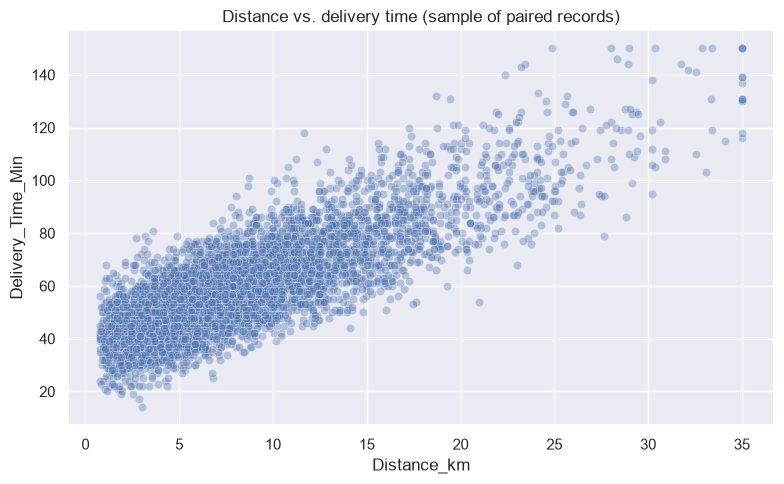

Delivered orders with both values: 88099
Delivered-only Pearson correlation: 0.8288


,Orders,Average_Distance,Average_Delivery_Time,Median_Delivery_Time
Distance_Band,,,,
"(-0.001, 5.0]",25857,3.210,45.800,45.000
"(5.0, 10.0]",32638,7.310,57.170,57.000
"(10.0, 15.0]",17451,12.200,71.000,70.000
"(15.0, 20.0]",7443,17.150,84.730,84.000
"(20.0, 25.0]",3004,22.120,98.630,97.000
"(25.0, 35.0]",1706,29.160,117.800,117.000
"(35.0, 50.0]",0,NaN,NaN,NaN


In [12]:
if {"Distance_km", "Delivery_Time_Min"}.issubset(df_raw.columns):
    distance = pd.to_numeric(df_raw["Distance_km"], errors="coerce")
    delivery_time = pd.to_numeric(df_raw["Delivery_Time_Min"], errors="coerce")
    paired = pd.DataFrame({
        "Distance_km": distance,
        "Delivery_Time_Min": delivery_time
    }).dropna()

    print("Records with both distance and delivery time:", len(paired))
    if len(paired) >= 2:
        print("Pearson correlation:", round(paired["Distance_km"].corr(paired["Delivery_Time_Min"]), 4))
        print("Spearman correlation:", round(paired["Distance_km"].corr(paired["Delivery_Time_Min"], method="spearman"), 4))

        plt.figure(figsize=(8, 5))
        sns.scatterplot(
            data=paired.sample(min(5000, len(paired)), random_state=42),
            x="Distance_km", y="Delivery_Time_Min", alpha=0.35
        )
        plt.title("Distance vs. delivery time (sample of paired records)")
        plt.tight_layout()
        plt.show()

        if "Order_Status" in df_raw:
            delivered_mask = (
                df_raw["Order_Status"].astype("string").str.strip().str.casefold()
                .eq("delivered")
            )
            delivered_pairs = pd.DataFrame({
                "Distance_km": distance[delivered_mask],
                "Delivery_Time_Min": delivery_time[delivered_mask]
            }).dropna()
            print("Delivered orders with both values:", len(delivered_pairs))
            if len(delivered_pairs) >= 2:
                print("Delivered-only Pearson correlation:",
                      round(delivered_pairs["Distance_km"].corr(delivered_pairs["Delivery_Time_Min"]), 4))

    # Optional distance-band summary for observed paired records.
    if len(paired):
        paired["Distance_Band"] = pd.cut(
            paired["Distance_km"],
            bins=[0, 5, 10, 15, 20, 25, 35, 50],
            include_lowest=True
        )
        display(
            paired.groupby("Distance_Band", observed=False)
            .agg(
                Orders=("Delivery_Time_Min", "size"),
                Average_Distance=("Distance_km", "mean"),
                Average_Delivery_Time=("Delivery_Time_Min", "mean"),
                Median_Delivery_Time=("Delivery_Time_Min", "median")
            ).round(2)
        )
else:
    print("Distance/time relationship check skipped: required columns not found.")

## 10. Revenue and profit field audit


In [13]:
financial_fields = [
    column for column in [
        "Order_Value", "Discount_Applied", "Delivery_Fee",
        "Tax", "Final_Amount", "Profit_Margin"
    ] if column in df_raw.columns
]

if financial_fields:
    display(df_raw[financial_fields].describe().T)

if "Profit_Margin" in df_raw:
    margin = pd.to_numeric(df_raw["Profit_Margin"], errors="coerce")
    print("Profit_Margin non-null count:", int(margin.notna().sum()))
    print("Profit_Margin minimum:", margin.min())
    print("Profit_Margin maximum:", margin.max())
    print(
        "Interpretation reminder: confirm whether Profit_Margin is a ratio or percentage "
        "and whether it is derived from actual cost fields before using it as a business KPI."
    )

,count,mean,std,min,25%,50%,75%,max
Order_Value,"99,501.000","1,085.017",626.832,183.310,623.130,945.040,"1,393.400","5,000.000"
Discount_Applied,"99,500.000",76.088,83.284,0.000,0.000,50.000,115.180,300.000
Final_Amount,"99,003.000","1,008.933",627.608,120.840,543.745,867.020,"1,319.105","5,000.000"
Profit_Margin,"89,288.000",0.176,0.072,-0.050,0.128,0.177,0.225,0.380


Profit_Margin non-null count: 89288
Profit_Margin minimum: -0.05
Profit_Margin maximum: 0.38
Interpretation reminder: confirm whether Profit_Margin is a ratio or percentage and whether it is derived from actual cost fields before using it as a business KPI.


## 11. Export audit outputs


In [14]:
# Save machine-readable audit outputs.
missing_audit.to_csv(REPORT_DIR / "missing_value_audit.csv")

if not numeric_summary.empty:
    numeric_summary.to_csv(REPORT_DIR / "numeric_summary.csv")

business_rule_audit.to_csv(REPORT_DIR / "business_rule_audit.csv", index=False)

for column, table in category_tables.items():
    safe_name = "".join(ch.lower() if ch.isalnum() else "_" for ch in column)
    table.to_csv(REPORT_DIR / f"category_audit_{safe_name}.csv", index=False)

summary_lines = [
    "Online Food Delivery Analysis — Raw Dataset Audit",
    "=" * 52,
    f"Source file: {RAW_FILE}",
    f"Rows: {df_raw.shape[0]}",
    f"Columns: {df_raw.shape[1]}",
    f"Exact duplicate rows: {int(df_raw.duplicated().sum())}",
    f"Columns with missing values: {int((df_raw.isna().sum() > 0).sum())}",
    f"Total missing cells: {int(df_raw.isna().sum().sum())}",
    "",
    "Missing values by column:",
    missing_audit.to_string(),
    "",
    "Business-rule flags:",
    business_rule_audit.to_string(index=False),
    "",
    "Reminder: flagged records are investigation candidates, not automatic deletion/imputation instructions.",
    "The source dataset is synthetic and should be described as such."
]
summary_path = REPORT_DIR / "raw_data_audit_summary.txt"
summary_path.write_text("\n".join(summary_lines), encoding="utf-8")

print("Audit outputs saved to:", REPORT_DIR)
print("Summary:", summary_path)
print("Raw dataset unchanged:", RAW_FILE.exists())

Audit outputs saved to: D:\online food delivery analysis final\reports
Summary: D:\online food delivery analysis final\reports\raw_data_audit_summary.txt
Raw dataset unchanged: True
